In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

P = Path("..") / "data" / "processed"
w = pd.read_parquet(P / "category_weekly_style0.3.parquet")
w0 = pd.read_parquet(P / "category_weekly_style0.0.parquet")
w.head()

,articleType,week,sales,price,promo
0,Casual Shoes,2021-01-04,695,62.35826,0
1,Casual Shoes,2021-01-11,695,62.35826,0
2,Casual Shoes,2021-01-18,626,62.35826,0
3,Casual Shoes,2021-01-25,534,62.35826,0
4,Casual Shoes,2021-02-01,543,62.35826,0


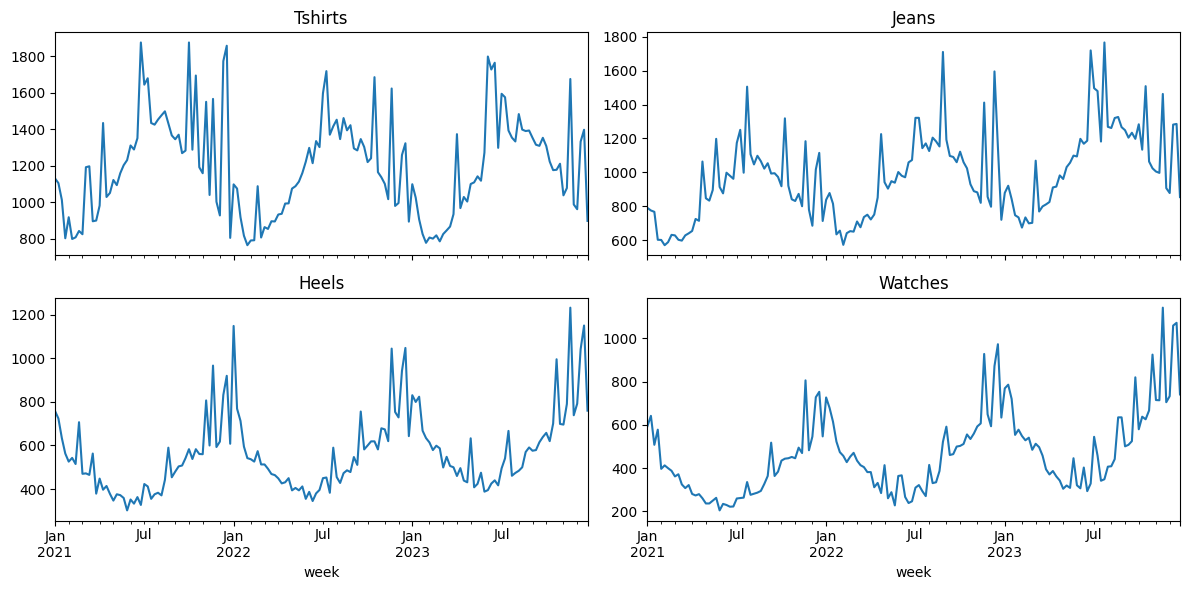

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, cat in zip(axes.ravel(), ["Tshirts", "Jeans", "Heels", "Watches"]):
    s = w[w.articleType == cat].set_index("week")["sales"]
    s.plot(ax=ax, title=cat)
plt.tight_layout()
plt.show()

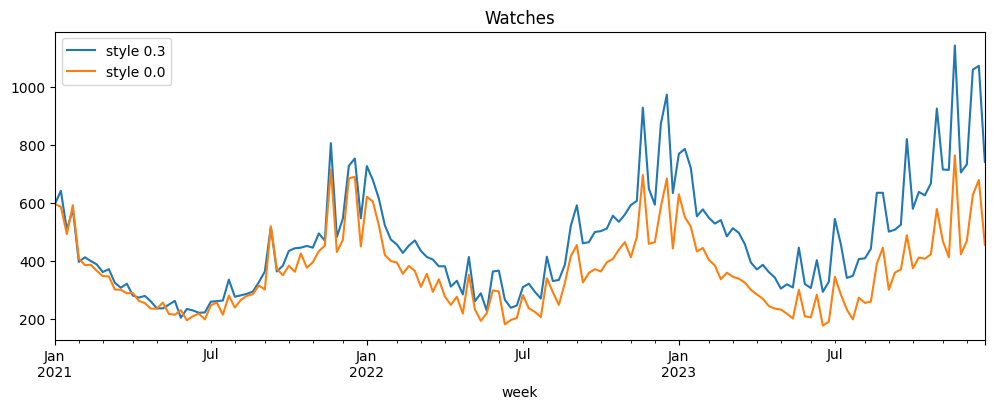

In [3]:
cat = "Watches"
a = w[w.articleType == cat].set_index("week")["sales"]
b = w0[w0.articleType == cat].set_index("week")["sales"]
pd.DataFrame({"style 0.3": a, "style 0.0": b}).plot(figsize=(12, 4), title=cat)
plt.show()

In [4]:
print(w.groupby(["articleType", "promo"])["sales"].mean().unstack().round(0))

promo              0       1
articleType                 
Casual Shoes   688.0   932.0
Handbags       460.0   611.0
Heels          552.0   746.0
Jeans          950.0  1426.0
Shirts        1003.0  1309.0
Shorts         850.0  1232.0
Sports Shoes   709.0   959.0
Tops           922.0  1412.0
Tshirts       1157.0  1592.0
Watches        460.0   545.0
